# 04 · OOD (run once) + spot maps

Output of the deployed model: **no TLS / TLS + confidence** (confidence = max(P, 1 − P)). The maturity head showed no signal in CV / test (notebook 03) and is not part of the output.

Locked cohorts: **Internal lung** (local data, aggregated metrics only) and **CPTAC-PAAD**. The model is used exactly as saved by notebook 03 — no tuning after this point.

In [1]:
import logging, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
(ROOT / "results").mkdir(exist_ok=True)
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s %(message)s",
                    handlers=[logging.StreamHandler(sys.stdout), logging.FileHandler(ROOT / "results" / "notebooks.log")],
                    force=True)
for noisy in ("anndata", "fsspec", "matplotlib", "PIL"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tls_model import pipeline
cfg = pipeline.load_config()
paths = {k: ROOT / v for k, v in cfg["paths"].items()}
FIG = paths["results"] / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
import pickle
import anndata as ad
from tls_model import prepare, evaluate

units, meta = prepare.load_units(cfg, ROOT)
obs = units.obs
with open(ROOT / "models" / "tls_model.pkl", "rb") as handle:
    saved = pickle.load(handle)
variant = saved["variant"]
B, names = pipeline.feature_matrix(units, meta, variant["representation"], bool(variant["offset"]))
p_tls = pipeline.predict(B, names, obs, saved["models"]["any"], saved["calibrators"]["any"])
confidence = np.maximum(p_tls, 1 - p_tls)
print("variant:", variant, "| model:", saved["best"]["any"])
print(obs.loc[obs["split"] == "ood"].groupby("cohort", observed=True).size())

variant: {'representation': 'rank', 'offset': False} | model: {'family': 'lgbm', 'selector': 'shap'}
cohort
CPTAC-PAAD       129
Internal_lung     47
dtype: int64


## OOD metrics (95% bootstrap CI)

In [3]:
ood = pipeline.evaluate_split(obs, p_tls, None, "ood")
ood.to_csv(paths["results"] / "ood_metrics.tsv", sep="	", index=False)
evaluate.metrics_table(ood.to_dict("records"))

,split,head,block,n,n_pos,auroc,auprc,brier
0,ood,any,bulk:CPTAC-PAAD,129,54,"0.641 [0.543, 0.738]","0.610 [0.492, 0.726]","0.248 [0.230, 0.266]"
1,ood,any,bulk:Internal_lung,47,17,"0.855 [0.742, 0.950]","0.797 [0.613, 0.929]","0.211 [0.176, 0.248]"
2,ood,any,bulk:all,176,71,"0.705 [0.630, 0.780]","0.655 [0.547, 0.758]","0.238 [0.221, 0.255]"


## Calls and confidence per OOD cohort (aggregates only)

In [4]:
m = (obs["split"] == "ood").to_numpy()
calls = pd.DataFrame({"cohort": obs["cohort"][m], "tls_true": obs["tls_any"][m], "tls_call": p_tls[m] >= 0.5,
                      "p_tls": p_tls[m], "confidence": confidence[m]})
calls.groupby("cohort").agg(n=("tls_true", "size"), tls_true=("tls_true", "sum"), tls_called=("tls_call", "sum"),
                            accuracy=("tls_call", lambda s: float((s == calls.loc[s.index, "tls_true"]).mean())),
                            mean_p=("p_tls", "mean"), mean_confidence=("confidence", "mean")).round(3)

,n,tls_true,tls_called,accuracy,mean_p,mean_confidence
cohort,,,,,,
,0,0.0,0,NaN,NaN,NaN
CPTAC-PAAD,129,54.0,97,0.574,0.564,0.590
CPTAC-ccRCC,0,0.0,0,NaN,NaN,NaN
Internal_lung,47,17.0,29,0.660,0.565,0.628
MGH_LUAD_DagogoJack,0,0.0,0,NaN,NaN,NaN
TCGA-BRCA,0,0.0,0,NaN,NaN,NaN
TCGA-KIRC/KIRP/KICH,0,0.0,0,NaN,NaN,NaN
TCGA-LUAD,0,0.0,0,NaN,NaN,NaN
TCGA-PAAD,0,0.0,0,NaN,NaN,NaN


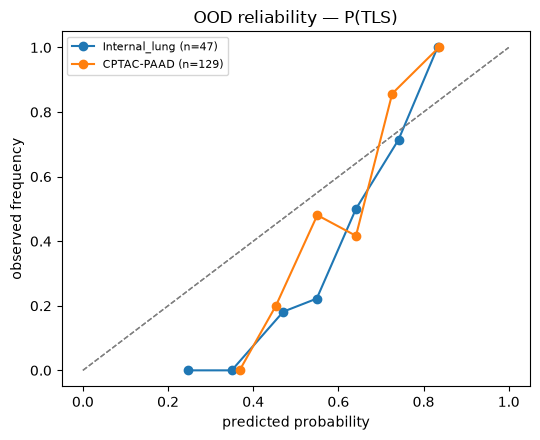

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
scored = pipeline.scored_rows(obs, "any", "ood")
y = obs["tls_any"].to_numpy(dtype=float)
for cohort in cfg["cohorts"]["ood"]:
    m = scored & (obs["cohort"] == cohort).to_numpy()
    if m.sum() > 10 and len(np.unique(y[m])) == 2:
        evaluate.reliability_curve(ax, y[m], p_tls[m], cohort)
ax.set_title("OOD reliability — P(TLS)")
fig.tight_layout(); fig.savefig(FIG / "04_reliability_ood.png", dpi=120)

## Spot maps on held-out Visium sections

Left: expert label. Right: P(TLS) on one colour scale shared by all shown sections, capped at the 99th percentile of their spots (spot probabilities are low: TLS cover ~4% of spots), so weak signal stays visible.

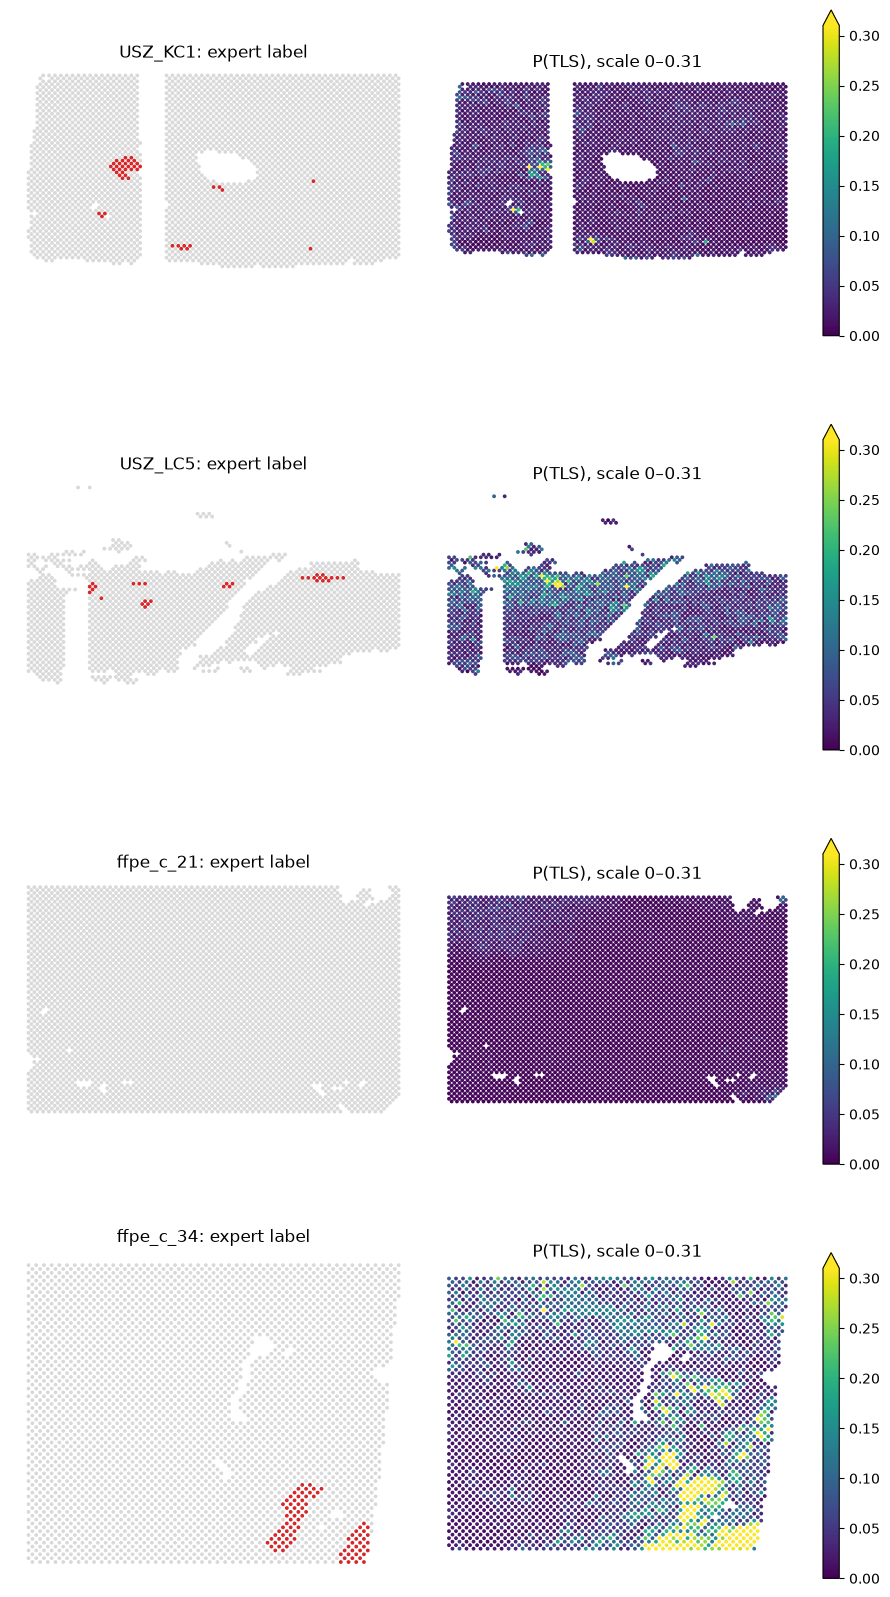

In [6]:
test_sections = obs.loc[(obs["split"] == "test") & (obs["unit"] == "spot"), "section"].unique()
show = sorted(test_sections, key=lambda s: (not s.startswith("USZ"), s))[:4]
shown = (obs["section"].isin(show) & (obs["unit"] == "spot")).to_numpy()
vmax = float(np.ceil(np.quantile(p_tls[shown], 0.99) * 100) / 100)
fig, axes = plt.subplots(len(show), 2, figsize=(9, 4.2 * len(show)))
axes = np.atleast_2d(axes)
for row, section in zip(axes, show):
    spots = ((obs["section"] == section) & (obs["unit"] == "spot")).to_numpy()
    a = ad.read_h5ad(paths["visium_h5ad"] / f"{section}.h5ad", backed="r")
    barcodes = [i.split(":spot:")[1] for i in obs.index[spots]]
    coords = a.obs.loc[barcodes, ["array_row", "array_col"]]
    xs, ys = coords["array_col"].to_numpy(), -coords["array_row"].to_numpy()
    row[0].scatter(xs, ys, c=np.where(obs["tls_any"].to_numpy()[spots] == 1, "#d62728", "#d9d9d9"), s=3)
    dots = row[1].scatter(xs, ys, c=p_tls[spots], cmap="viridis", vmin=0, vmax=vmax, s=3)
    fig.colorbar(dots, ax=row[1], fraction=0.04, extend="max")
    row[0].set_title(f"{section}: expert label"); row[1].set_title(f"P(TLS), scale 0–{vmax:.2f}")
    for ax in row:
        ax.set_aspect("equal"); ax.axis("off")
fig.tight_layout(); fig.savefig(FIG / "04_spot_maps.png", dpi=110)